In [1]:
import os
import sys
import requests
import datetime as dt
import numpy as np
from dotenv import load_dotenv
from pathlib import Path
import requests
import pandas as pd
import talib as ta
import plotly.graph_objs as go

import ipywidgets as widgets
from ipywidgets import Dropdown, Text, Button, Output
from IPython.display import display

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

### WTIの時系列データを取得

In [3]:
wti = 'CL=F'
start = '1999-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
response = request_api.update_commodity_timeseries_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [4]:
wti_df = request_api.get_commodity_time_series_data(
    code=wti,
    market=None,
    start=start,
    end=end
)
wti_df.head()

取得件数: 6542


,id,commodity_id,commodity_code,commodity_market,date,open,high,low,close,adj_close,...,rci9,rci26,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,6530,2,CL=F,None,2000-08-23,32.049999,32.799999,31.950001,31.950001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,6531,2,CL=F,None,2000-08-24,31.629999,32.240002,31.400000,31.900000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,6532,2,CL=F,None,2000-08-25,32.049999,32.099998,31.320000,31.700001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,6533,2,CL=F,None,2000-08-28,32.869999,32.919998,31.860001,32.040001,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,6534,2,CL=F,None,2000-08-29,32.720001,33.029999,32.560001,32.820000,None,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### S&P500の時系列データを取得

In [5]:
sp500 = '^GSPC'

response = request_api.update_stock_timeseries_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
response

{'result': True}

In [6]:
sp_timeseries_df = request_api.get_stock_time_series_data(
    code=sp500,
    market=None,
    start=start,
    end=end
)
sp_timeseries_df.head()

取得件数: 6996


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,upper1,lower1,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1064856,^GSPC,None,1998-11-17,1139.319946,1151.709961,1129.670044,1135.869995,705200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1064857,^GSPC,None,1998-11-18,1144.479980,1144.520020,1133.069946,1139.319946,652510000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1064858,^GSPC,None,1998-11-19,1152.609985,1155.099976,1144.420044,1144.479980,671000000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1064859,^GSPC,None,1998-11-20,1163.550049,1163.550049,1152.609985,1152.609985,721200000,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1064860,^GSPC,None,1998-11-23,1188.209961,1188.209961,1163.550049,1163.550049,774100000,1147.165991,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### 2222の時系列データを取得

In [8]:
alamco = '2222'
market = 'SR'

response = request_api.update_stock_timeseries_data(
    code=alamco,
    market=market,
    start=start,
    end=end
)
response

{'result': True}

In [9]:
alamco_timeseries_df = request_api.get_stock_time_series_data(
    code=alamco,
    market=market,
    start=start,
    end=end
)
alamco_timeseries_df

取得件数: 1689


,id,stock_code,stock_market,date,open,high,low,close,volume,ma5,...,upper1,lower1,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
0,1088196,2222,SR,2019-12-11,21.520967,21.520967,21.520967,21.520967,38289394,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1,1088197,2222,SR,2019-12-12,22.499191,23.660834,22.010078,23.660834,505692621,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2,1088198,2222,SR,2019-12-15,22.866026,22.927166,22.499192,22.682610,98349281,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
3,1088199,2222,SR,2019-12-16,23.232857,23.293995,22.927161,22.927161,105973907,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
4,1088200,2222,SR,2019-12-17,23.080011,23.324567,22.927164,23.263428,142672245,22.811,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1684,1089880,2222,SR,2026-09-06,25.959999,26.100000,25.900000,26.020000,6688799,26.116,...,26.457564,26.109136,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1685,1089881,2222,SR,2026-09-08,26.059999,26.200001,25.920000,25.959999,8253373,26.064,...,26.451858,26.082847,False,NaN,NaN,NaN,NaN,NaN,NaN,False
1686,1089882,2222,SR,2026-09-09,26.040001,26.200001,26.020000,26.059999,5730398,26.052,...,26.376299,26.093341,False,NaN,NaN,NaN,NaN,-60.833333,NaN,False
1687,1089883,2222,SR,2026-09-10,26.139999,26.180000,26.020000,26.020000,5010055,26.016,...,26.354877,26.078091,False,NaN,NaN,NaN,NaN,NaN,NaN,False


#### チャート

In [10]:
def stock_prices_and_oil_prices(
        code: str,
        name: str,
        start: str,
        end: str,
        market: str | None = None,
        df_sp: pd.DataFrame | None = None,
        df_wti: pd.DataFrame | None = None,
    ):
    # /api/v1/time_series_data/stock/
    response = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start,
        end=end
    )
    df_stock = pd.DataFrame(response)

    # S&P500を統合
    if df_sp is not None:
        df_sp_tmp = df_sp.copy() if df_sp is not None else pd.DataFrame()
        if "date" not in df_sp_tmp.columns:
            df_sp_tmp = df_sp_tmp.reset_index()

        df_sp_tmp["date"] = pd.to_datetime(df_sp_tmp["date"])
        df_sp_tmp = df_sp_tmp.set_index("date")
        df_sp_tmp = df_sp_tmp.loc[start:end]

    # WTI原油価格を統合
    if df_wti is not None:
        df_wti_tmp = df_wti.copy() if df_wti is not None else pd.DataFrame()
        if "date" not in df_wti_tmp.columns:
            df_wti_tmp = df_wti_tmp.reset_index()
        df_wti_tmp["date"] = pd.to_datetime(df_wti_tmp["date"])
        df_wti_tmp = df_wti_tmp.set_index("date")
        df_wti_tmp = df_wti_tmp.loc[start:end]

    # 株価時系列データを整形
    df = df_stock.copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.set_index("date")
    df = df.loc[start:end]


    # インデックスを揃えて結合
    if df_sp is not None:
        df["MA5_SP"] = df_sp_tmp["ma5"].reindex(df.index)
        df["MA25_SP"] = df_sp_tmp["ma25"].reindex(df.index)
    if df_wti is not None:
        df["MA5_WTI"] = df_wti_tmp["ma5"].reindex(df.index)
        df["MA25_WTI"] = df_wti_tmp["ma25"].reindex(df.index)

    show_plot = ShowPlot()
    fig = show_plot.create_basic_chart(
        df=df.reset_index(),
        code=code,
        name=name,
        start=start,
        end=end
    )
    # ★ 2つのY軸を定義（左：HYMC、右：SP500 & GOLD）
    fig.update_layout(
        yaxis=dict(
            title=f"{name} Price",
            side="left"
        ),
        yaxis2=dict(
            title="SP500 / WTI",
            overlaying="y",
            side="right"
        )
    )

    # --- SP500（右軸） ---
    if df_sp is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA5_SP"],
                name="SP_MA5",
                line={"color": "blue", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA25_SP"],
                name="SP_MA25",
                line={"color": "gray", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    # --- WTI（右軸） ---
    if df_wti is not None:
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA5_WTI"],
                name="WTI_MA5",
                line={"color": "orange", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )
        fig.add_trace(
            go.Scatter(
                x=df.index,
                y=df["MA25_WTI"],
                name="WTI_MA25",
                line={"color": "yellow", "width": 1.2},
                yaxis="y2"   # ★ 右軸
            )
        )

    return fig

In [12]:
name = "Saudi Arabian Oil Company"
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
end = dt.datetime.now().strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=alamco,
    name=name,
    start=start,
    end=end,
    market=market,
    df_sp=None,
    df_wti=wti_df
)
fig.show()

取得件数: 629


In [13]:
# 例: すでに作成済みの fig を保存
output_dir = Path("/workspace/data/figures")
output_dir.mkdir(parents=True, exist_ok=True)
# ファイル名にコードと期間を含める
output_path = output_dir / f"{alamco}_{start}_{end}.png"
fig.write_image(str(output_path), width=1600, height=900, scale=2)
# 保存完了のメッセージを表示
print("saved:", output_path)

saved: /workspace/data/figures/2222_2025-01-01_2026-09-14.png


In [14]:
start = dt.datetime(2025, 1, 1).strftime("%Y-%m-%d")
# グラフ領域の作成
fig = stock_prices_and_oil_prices(
    code=alamco,
    name=name,
    start=start,
    end=end,
    market=market,
    df_sp=None,
    df_wti=None
)
fig.show()

取得件数: 629


#### 時系列データを保存

In [15]:
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{alamco}_data_{dt.datetime.now().strftime('%Y-%m-%d')}.csv"

df = alamco_timeseries_df.copy()
df = df.reset_index()
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.loc['2026-01-01':end]
df.to_csv(output_path)
df.tail()

,index,id,stock_code,stock_market,open,high,low,close,volume,ma5,...,upper1,lower1,cross,gc,dc,macd_gc,macd_dc,rci_gc,rci_dc,rising_condition
date,,,,,,,,,,,,,,,,,,,,,
2026-09-06,1684,1089880,2222,SR,25.959999,26.100000,25.90,26.020000,6688799,26.116,...,26.457564,26.109136,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-09-08,1685,1089881,2222,SR,26.059999,26.200001,25.92,25.959999,8253373,26.064,...,26.451858,26.082847,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-09-09,1686,1089882,2222,SR,26.040001,26.200001,26.02,26.059999,5730398,26.052,...,26.376299,26.093341,False,NaN,NaN,NaN,NaN,-60.833333,NaN,False
2026-09-10,1687,1089883,2222,SR,26.139999,26.180000,26.02,26.020000,5010055,26.016,...,26.354877,26.078091,False,NaN,NaN,NaN,NaN,NaN,NaN,False
2026-09-13,1688,1089884,2222,SR,NaN,NaN,NaN,NaN,7258821,NaN,...,NaN,NaN,False,NaN,NaN,NaN,NaN,NaN,NaN,False


{'fib_levels_down': {'1.000': np.float64(25.570123826685645),
  '1.272': np.float64(25.110052472441467),
  '1.382': np.float64(24.923994204180953),
  '1.618': np.float64(24.52481464682203)},
 'fib_levels_up': {'1.272': np.float64(27.72163398329813),
  '1.382': np.float64(27.907692251558643),
  '1.618': np.float64(28.306871808917567),
  '2.000': np.float64(28.95300143142226)},
 'swing_high': np.float64(27.26156262905395),
 'swing_low': np.float64(25.570123826685645),
 'df_with_fib':           date  index       id stock_code stock_market       open       high  \
 0   2026-01-01   1514  1089710       2222           SR  22.991533  23.030046   
 1   2026-01-04   1515  1089711       2222           SR  22.625671  23.001161   
 2   2026-01-05   1516  1089712       2222           SR  22.539021  22.673811   
 3   2026-01-06   1517  1089713       2222           SR  22.567905  22.721952   
 4   2026-01-07   1518  1089714       2222           SR  22.702694  22.914508   
 ..         ...    ...      

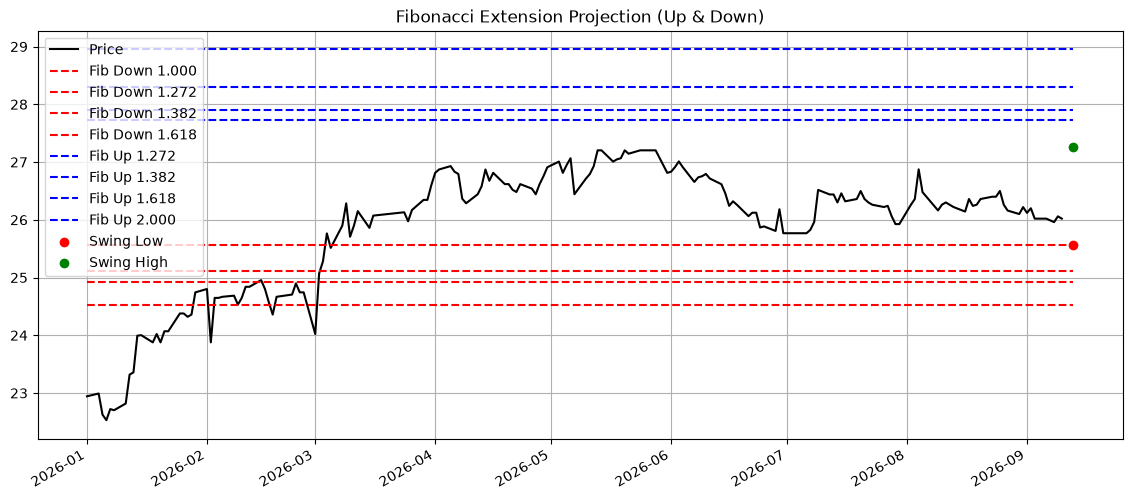

In [16]:
fib_result = fibonacci_extension.compute_fibonacci_extension(df.copy().reset_index())
fib_result

In [17]:
output_dir = Path("/workspace/data/figures/")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / f"{alamco}_fibonacci_extension_{dt.datetime.now().strftime('%Y-%m-%d')}.png"
fib_result["plot_obj"].savefig(output_path, dpi=300, bbox_inches="tight")

#### 財務データ

In [18]:
response = request_api.update_corp_finance_data(
    code=alamco,
    market=None
)
response

{'result': True}

In [19]:
alamco_financials_data = request_api.get_corp_financials_data(code=alamco, market=None)
alamco_balance_sheet_data = request_api.get_corp_balance_sheet_data(code=alamco, market=None)
alamco_cash_flow_data = request_api.get_corp_cash_flow_data(code=alamco, market=None)
alamco_earnings_data = request_api.get_corp_earnings_data(code=alamco, market=None)
alamco_quarterly_earnings_data = request_api.get_corp_quarterly_earnings_data(code=alamco, market=None)

GET response: {'detail': 'Corporate finance data not found'}
GET response: {'detail': 'Balance sheet data not found'}
GET response: {'detail': 'Cash flow data not found'}
GET response: {'detail': 'Earnings data not found'}
GET response: {'detail': 'Quarterly earnings data not found'}
